# Lab Khai phá dữ liệu - Red Wine Quality
**Trần Minh Tấn - 6451071071**

## Cell 1: Cài đặt, kết nối dữ liệu và nhập dữ liệu

In [1]:
!pip install -q gdown

import gdown, pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns

HO_TEN = "Trần Minh Tấn"
MSSV   = "6451071071"

def info(cau=""):
    print("=" * 55)
    print(f"Họ tên : {HO_TEN}")
    print(f"MSSV   : {MSSV}")
    if cau:
        print(f"Nội dung: {cau}")
    print("=" * 55)

info("Nhập dữ liệu Red Wine Quality")

FILE_ID = "1rzLiUi64RLmMV8ApudCt6aJyv_OkhADH"   # winequality-red.csv
gdown.download(id=FILE_ID, output="winequality-red.csv", quiet=False)

df = pd.read_csv("winequality-red.csv")   # nếu file dùng dấu ';' thì đổi thành sep=";"
print("Kích thước dữ liệu:", df.shape)
print("Số ô dữ liệu trống:", df.isna().sum().sum())
df.head()

Họ tên : Trần Minh Tấn
MSSV   : 6451071071
Nội dung: Nhập dữ liệu Red Wine Quality


Downloading...
From: https://drive.google.com/uc?id=1rzLiUi64RLmMV8ApudCt6aJyv_OkhADH
To: /content/winequality-red.csv
100%|██████████| 101k/101k [00:00<00:00, 46.1MB/s]

Kích thước dữ liệu: (1599, 12)
Số ô dữ liệu trống: 0


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


## Cell 2: Câu 3 - Độ tương đồng Pearson

Họ tên : Trần Minh Tấn
MSSV   : 6451071071
Nội dung: Câu 3 - Độ tương đồng Pearson


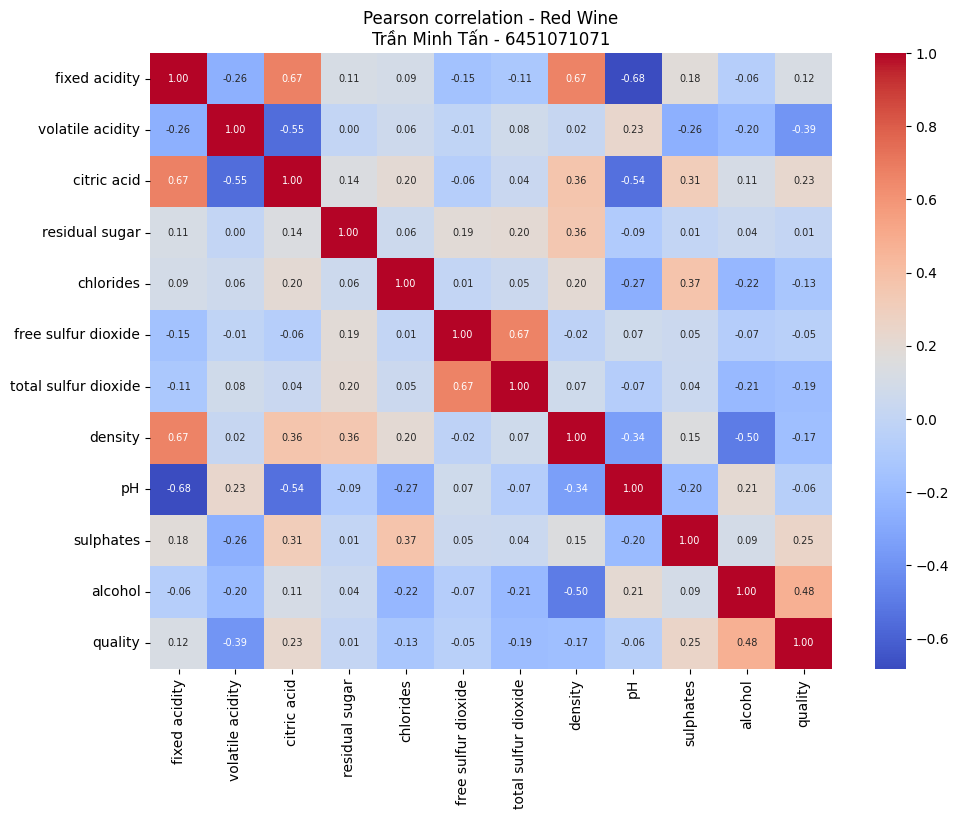

citric acid - fixed acidity = 0.67
total sulfur dioxide - free sulfur dioxide = 0.67
density - fixed acidity = 0.67
pH - fixed acidity = -0.68

Cột bị loại (|r| > 0.8): Không có cột nào


In [2]:
info("Câu 3 - Độ tương đồng Pearson")

corr = df.corr(method="pearson")

plt.figure(figsize=(11,8))
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f", annot_kws={"size":7})
plt.title(f"Pearson correlation - Red Wine\n{HO_TEN} - {MSSV}")
plt.show()

# Xét tương đồng giữa các thuộc tính (không tính cột quality)
feat_corr = df.drop(columns="quality").corr(method="pearson")

THRESH = 0.8
to_drop = set()
for i in range(len(feat_corr.columns)):
    for j in range(i):
        r = feat_corr.iloc[i, j]
        if abs(r) > 0.6:
            print(f"{feat_corr.columns[i]} - {feat_corr.columns[j]} = {r:.2f}")
        if abs(r) > THRESH:
            to_drop.add(feat_corr.columns[i])

print(f"\nCột bị loại (|r| > {THRESH}):", list(to_drop) if to_drop else "Không có cột nào")
df = df.drop(columns=list(to_drop))

## Cell 3: Câu 4 - Tách thuộc tính thường và thuộc tính quyết định

In [3]:
info("Câu 4 - Tách thuộc tính thường và thuộc tính quyết định (quality)")

X = df.drop(columns="quality")   # thuộc tính bình thường
y = df["quality"]                # thuộc tính quyết định

print("Kích thước X:", X.shape)
print("Kích thước y:", y.shape)
print("\nPhân bố nhãn quality:")
print(y.value_counts().sort_index())

Họ tên : Trần Minh Tấn
MSSV   : 6451071071
Nội dung: Câu 4 - Tách thuộc tính thường và thuộc tính quyết định (quality)
Kích thước X: (1599, 11)
Kích thước y: (1599,)

Phân bố nhãn quality:
quality
3     10
4     53
5    681
6    638
7    199
8     18
Name: count, dtype: int64


## Cell 4: Câu 5 - Chuyển đổi cột không phải dạng số sang one-hot vector

In [4]:
info("Câu 5 - Chuyển đổi cột không phải dạng số sang one-hot vector")

cat_cols = X.select_dtypes(exclude=np.number).columns
print("Các cột không phải dạng số:", list(cat_cols) if len(cat_cols) else "Không có (toàn bộ đã là dạng số)")

if len(cat_cols):
    X = pd.get_dummies(X, columns=cat_cols, dtype=int)

print("Kích thước X sau xử lý:", X.shape)

Họ tên : Trần Minh Tấn
MSSV   : 6451071071
Nội dung: Câu 5 - Chuyển đổi cột không phải dạng số sang one-hot vector
Các cột không phải dạng số: Không có (toàn bộ đã là dạng số)
Kích thước X sau xử lý: (1599, 11)


## Cell 5: Câu 6 - Tách dữ liệu thành tập huấn luyện (70%) và kiểm thử (30%)

In [5]:
info("Câu 6 - Chia dữ liệu huấn luyện 70% và kiểm thử 30%")

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

print("X_train:", X_train.shape, "| y_train:", y_train.shape)
print("X_test :", X_test.shape,  "| y_test :", y_test.shape)

Họ tên : Trần Minh Tấn
MSSV   : 6451071071
Nội dung: Câu 6 - Chia dữ liệu huấn luyện 70% và kiểm thử 30%
X_train: (1119, 11) | y_train: (1119,)
X_test : (480, 11) | y_test : (480,)


## Cell 6: Câu 7 - Cây ID3

Họ tên : Trần Minh Tấn
MSSV   : 6451071071
Nội dung: Câu 7 - Cây ID3
Accuracy ID3: 0.5792
              precision    recall  f1-score   support

           3       0.00      0.00      0.00         1
           4       0.50      0.06      0.11        17
           5       0.63      0.77      0.69       195
           6       0.54      0.53      0.53       200
           7       0.49      0.36      0.42        61
           8       0.00      0.00      0.00         6

    accuracy                           0.58       480
   macro avg       0.36      0.29      0.29       480
weighted avg       0.56      0.58      0.56       480



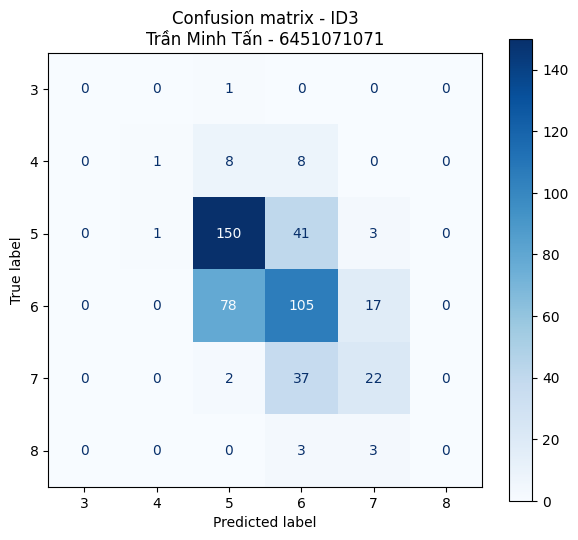

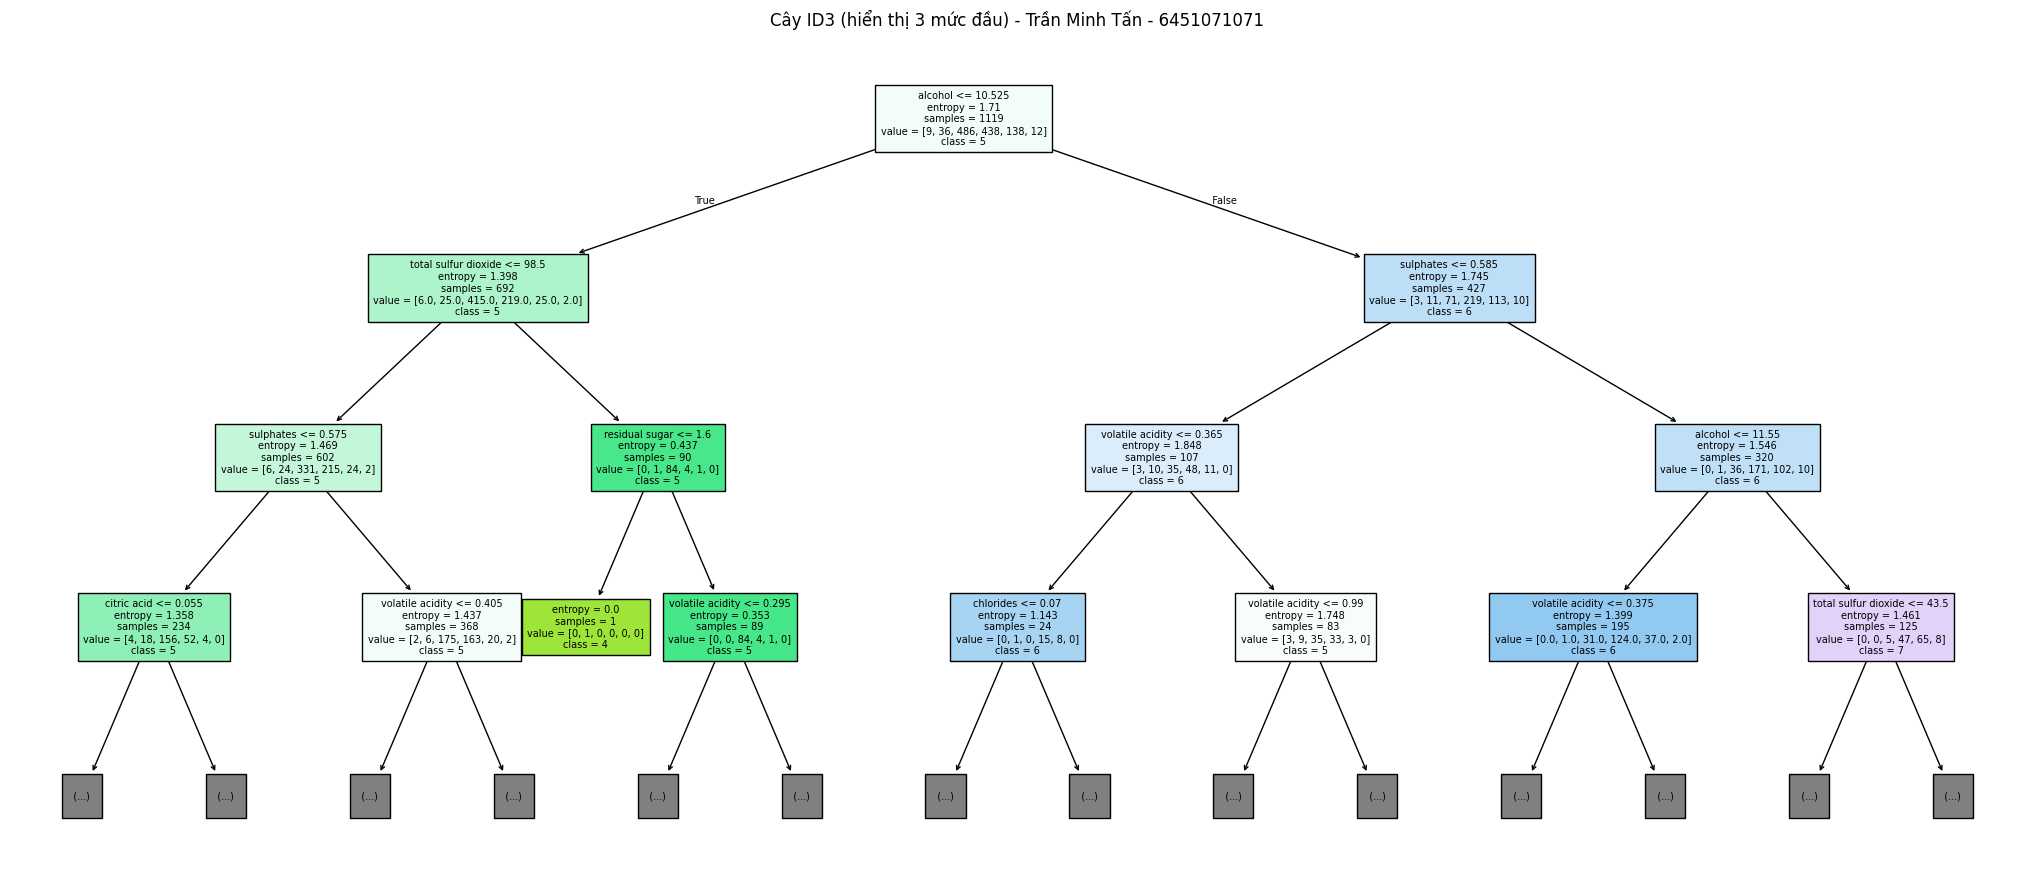

In [6]:
info("Câu 7 - Cây ID3")

from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, precision_score, recall_score, f1_score)

# ID3 dùng entropy (information gain)
id3 = DecisionTreeClassifier(criterion="entropy", max_depth=5, random_state=42)
id3.fit(X_train, y_train)
pred_id3 = id3.predict(X_test)

print("Accuracy ID3:", round(accuracy_score(y_test, pred_id3), 4))
print(classification_report(y_test, pred_id3, zero_division=0))

labels = sorted(y.unique())
fig, ax = plt.subplots(figsize=(7,6))
ConfusionMatrixDisplay.from_predictions(y_test, pred_id3, labels=labels, cmap="Blues", ax=ax)
ax.set_title(f"Confusion matrix - ID3\n{HO_TEN} - {MSSV}")
plt.show()

plt.figure(figsize=(26,11))
plot_tree(id3, feature_names=X_train.columns, class_names=[str(c) for c in id3.classes_],
          filled=True, fontsize=7, max_depth=3)
plt.title(f"Cây ID3 (hiển thị 3 mức đầu) - {HO_TEN} - {MSSV}")
plt.show()

## Cell 7: Câu 8 - Cây CART

Họ tên : Trần Minh Tấn
MSSV   : 6451071071
Nội dung: Câu 8 - Cây CART
Accuracy CART: 0.5687
              precision    recall  f1-score   support

           3       0.00      0.00      0.00         1
           4       0.00      0.00      0.00        17
           5       0.62      0.74      0.67       195
           6       0.53      0.54      0.53       200
           7       0.50      0.36      0.42        61
           8       0.00      0.00      0.00         6

    accuracy                           0.57       480
   macro avg       0.27      0.27      0.27       480
weighted avg       0.54      0.57      0.55       480



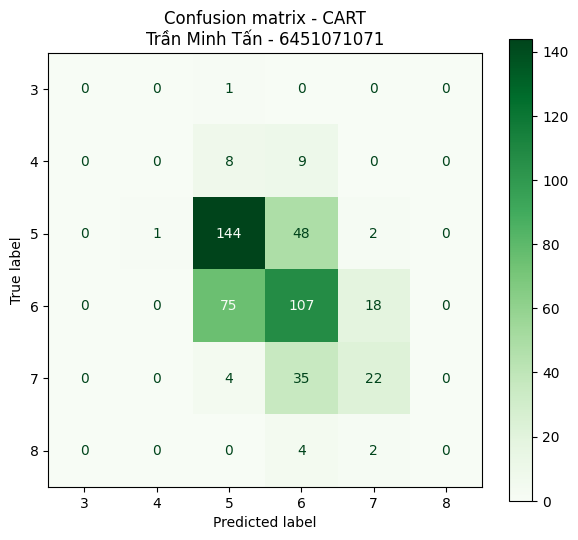

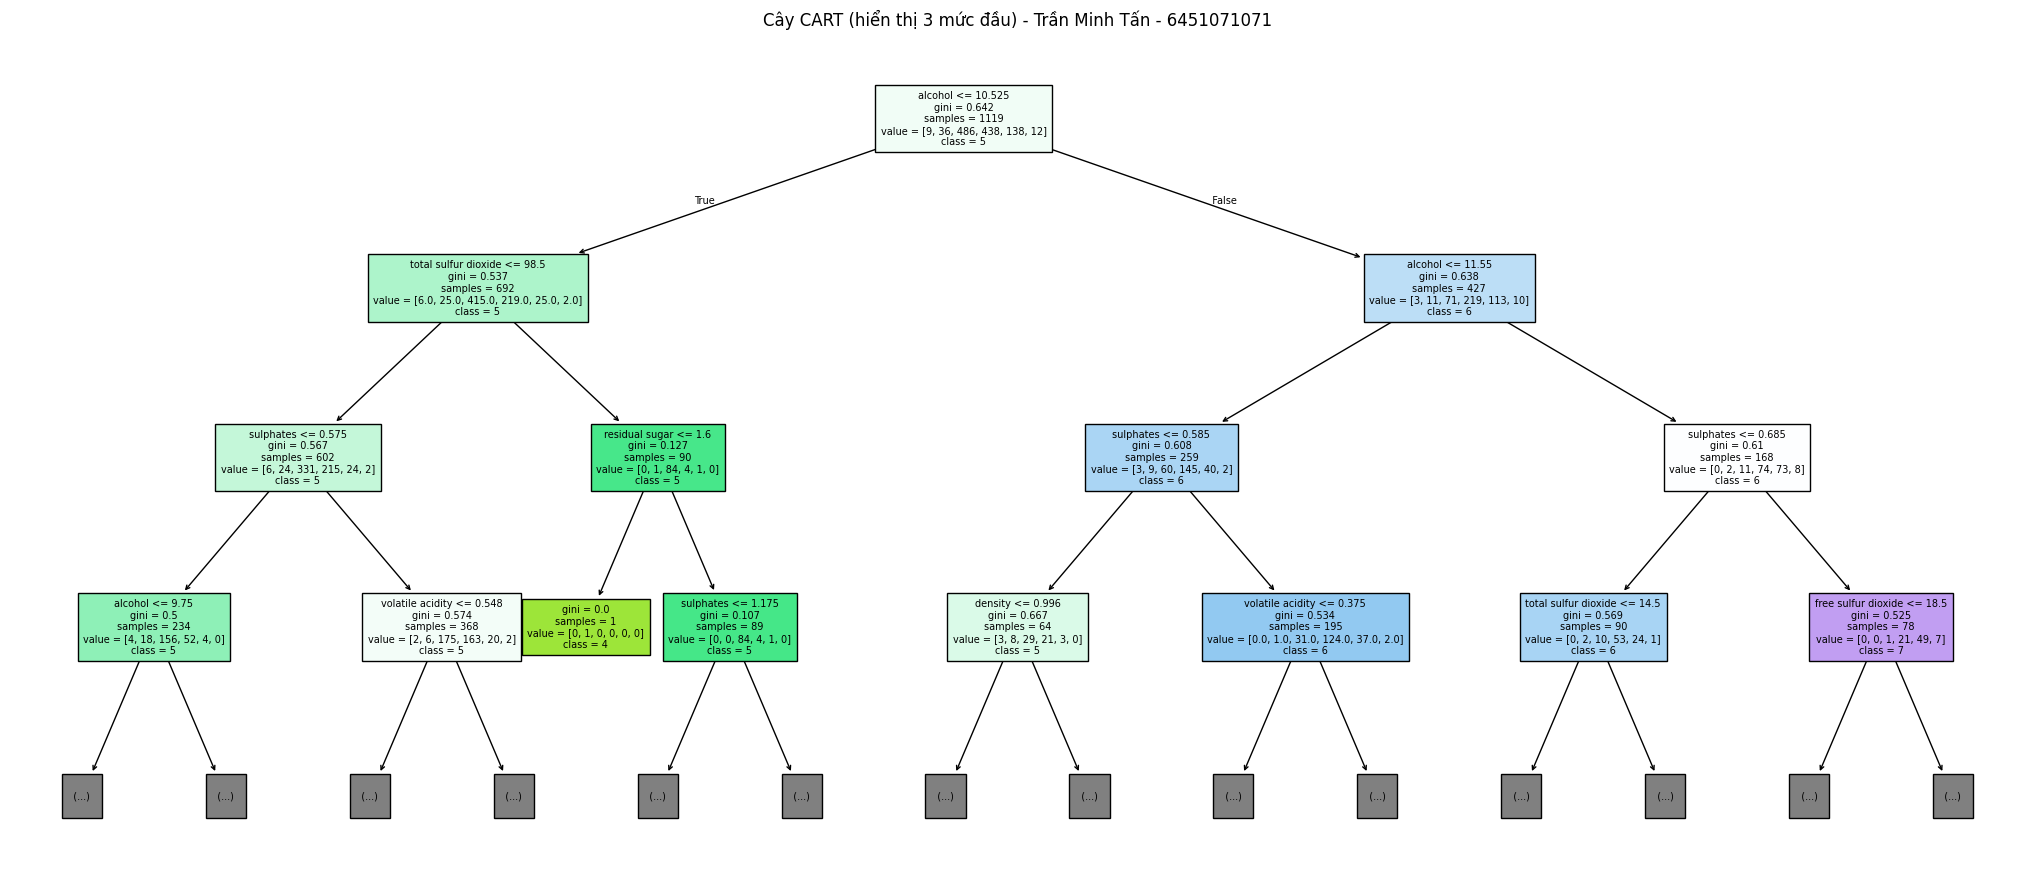

In [7]:
info("Câu 8 - Cây CART")

# CART dùng gini
cart = DecisionTreeClassifier(criterion="gini", max_depth=5, random_state=42)
cart.fit(X_train, y_train)
pred_cart = cart.predict(X_test)

print("Accuracy CART:", round(accuracy_score(y_test, pred_cart), 4))
print(classification_report(y_test, pred_cart, zero_division=0))

fig, ax = plt.subplots(figsize=(7,6))
ConfusionMatrixDisplay.from_predictions(y_test, pred_cart, labels=labels, cmap="Greens", ax=ax)
ax.set_title(f"Confusion matrix - CART\n{HO_TEN} - {MSSV}")
plt.show()

plt.figure(figsize=(26,11))
plot_tree(cart, feature_names=X_train.columns, class_names=[str(c) for c in cart.classes_],
          filled=True, fontsize=7, max_depth=3)
plt.title(f"Cây CART (hiển thị 3 mức đầu) - {HO_TEN} - {MSSV}")
plt.show()

## Cell 8: Câu 9 - Naive Bayes

Họ tên : Trần Minh Tấn
MSSV   : 6451071071
Nội dung: Câu 9 - Naive Bayes
Accuracy Naive Bayes: 0.5417
              precision    recall  f1-score   support

           3       0.00      0.00      0.00         1
           4       0.12      0.12      0.12        17
           5       0.68      0.62      0.65       195
           6       0.52      0.54      0.53       200
           7       0.40      0.49      0.44        61
           8       0.00      0.00      0.00         6

    accuracy                           0.54       480
   macro avg       0.29      0.29      0.29       480
weighted avg       0.55      0.54      0.54       480



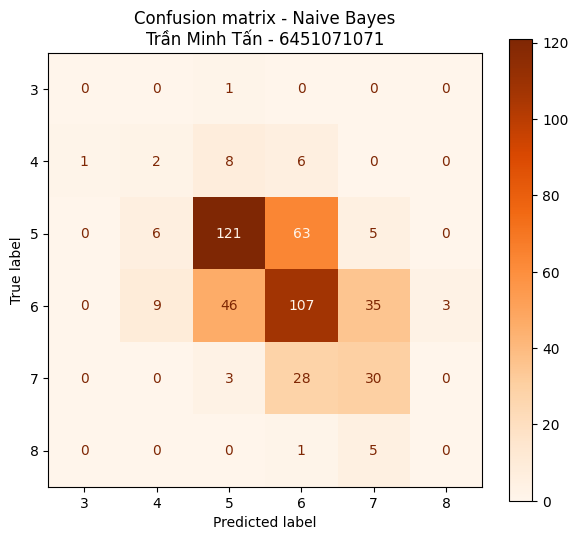

In [8]:
info("Câu 9 - Naive Bayes")

from sklearn.naive_bayes import GaussianNB

nb = GaussianNB()
nb.fit(X_train, y_train)
pred_nb = nb.predict(X_test)

print("Accuracy Naive Bayes:", round(accuracy_score(y_test, pred_nb), 4))
print(classification_report(y_test, pred_nb, zero_division=0))

fig, ax = plt.subplots(figsize=(7,6))
ConfusionMatrixDisplay.from_predictions(y_test, pred_nb, labels=labels, cmap="Oranges", ax=ax)
ax.set_title(f"Confusion matrix - Naive Bayes\n{HO_TEN} - {MSSV}")
plt.show()

## Cell 9: Câu 10 - So sánh kết quả các mô hình

Họ tên : Trần Minh Tấn
MSSV   : 6451071071
Nội dung: Câu 10 - So sánh kết quả các mô hình


,Accuracy,Precision,Recall,F1-score
Mô hình,,,,
ID3,0.5792,0.5603,0.5792,0.5594
CART,0.5688,0.5353,0.5688,0.5485
Naive Bayes,0.5417,0.5471,0.5417,0.5433


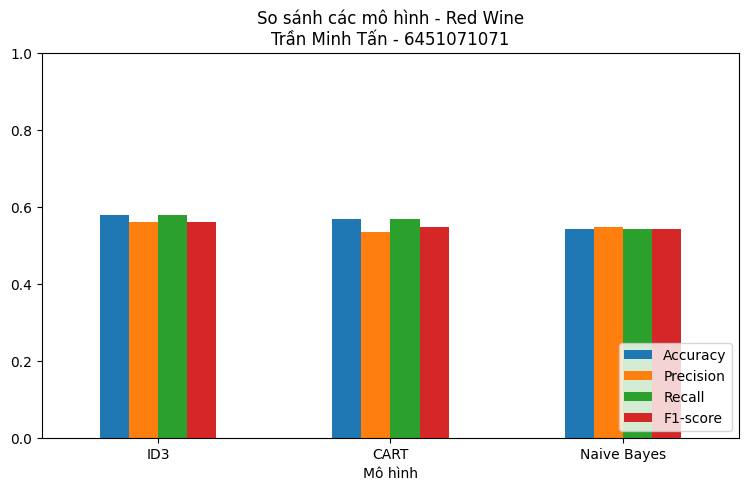

Mô hình có Accuracy cao nhất: ID3 (0.5792)


In [9]:
info("Câu 10 - So sánh kết quả các mô hình")

results = []
for name, pred in [("ID3", pred_id3), ("CART", pred_cart), ("Naive Bayes", pred_nb)]:
    results.append({
        "Mô hình":   name,
        "Accuracy":  accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, average="weighted", zero_division=0),
        "Recall":    recall_score(y_test, pred, average="weighted", zero_division=0),
        "F1-score":  f1_score(y_test, pred, average="weighted", zero_division=0),
    })

res = pd.DataFrame(results).set_index("Mô hình").round(4)
display(res)

res.plot(kind="bar", figsize=(9,5), ylim=(0,1))
plt.title(f"So sánh các mô hình - Red Wine\n{HO_TEN} - {MSSV}")
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.show()

best = res["Accuracy"].idxmax()
print(f"Mô hình có Accuracy cao nhất: {best} ({res.loc[best,'Accuracy']})")